<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_02_from_patents_to_a_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 2 · From patents to a network

*M2 Network Analysis · Mapping collaboration with networks*

**The story so far.** In Part 1 we learned how to store and build a network.

> **Today's question:** Patent records list which inventors worked on which application. How does that become a collaboration network, and what does it look like?

**You will learn to**

1. Recognise **two-mode (bipartite)** data and build an inventor–application graph.
2. Compute two-mode facts: team size and inventor productivity.
3. **Project** the two-mode graph onto inventors (and see projection as a matrix product).
4. Describe the result: weights, components and the connected *core*.

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

## 1. The data: European Patent Office inventors

A cleaned extract of EPO records. **Each row links one inventor to one patent application.**

| column | meaning |
|---|---|
| `appln_id` | patent application id |
| `inv_name` | inventor name |
| `person_id` | EPO person id |
| `city`, `ctry_code` | inventor's address |

One application can list several inventors, and one inventor can appear on many applications:
the table is **many-to-many**.

In [ ]:
URL = ("https://raw.githubusercontent.com/hamidb201214-svg/Lectures/"
       "refs/heads/main/data/epo_inventors_clean.csv")
df = pd.read_csv(URL, low_memory=False)      # UTF-8, so Danish letters (Ø, Å, Æ) survive
df[["appln_id", "inv_name", "city", "ctry_code"]].head(8)

,appln_id,inv_name,city,ctry_code
0,524471176,"VENDELBO, Allan Munk",Ballerup,DK
1,524471215,"BRØDSGAARD, Martin",NaN,DK
2,524471215,"SØRENSEN, Søren Hove",NaN,DK
3,524471215,"YVES DEBRUYNE, Yannick",Porto,PT
4,524471215,"SEAWARD, James",Aarhus,DK
5,524593647,"Ponnada, Sri Markandeya Rajesh",Aalborg,DK
6,524645416,"Jul Jacobsen, Niels",NaN,DK
7,524645416,"Haagaard, Oliver",Odense,DK


In [ ]:
print("rows        :", len(df))
print("applications:", df["appln_id"].nunique())
print("inventors   :", df["inv_name"].nunique(), "names /", df["person_id"].nunique(), "person ids")
df["ctry_code"].value_counts().head(8)

rows        : 6194
applications: 2101
inventors   : 3744 names / 4276 person ids


ctry_code
DK    5013
US     269
DE     209
FI     133
GB      82
IN      82
FR      66
CH      57
Name: count, dtype: int64

### ⚠️ A data-cleaning decision: who *is* an inventor?

There are more `person_id`s than names: the EPO often gives the **same person a new id** on a new application.

In [ ]:
ids_per_name = df.groupby("inv_name")["person_id"].nunique().sort_values(ascending=False)
print(ids_per_name.gt(1).sum(), "names have more than one person_id, e.g.")
ids_per_name.head(5)

447 names have more than one person_id, e.g.


inv_name
SELVAGANAPATHY, Srinivasan    7
CHANDRAMOULI, Devaki          6
NIKOLIC, Miroslav             6
ROSA, Claudio                 5
VITZRABIN, Efraim             4
Name: person_id, dtype: int64

If we used `person_id`, one prolific inventor would be split into many small "people" and their network would
fall apart. We therefore **use the name as the inventor key** (the risk: two different people with the same name
get merged). Every network starts with a decision like this — always state it.

In [ ]:
df = df.drop_duplicates(["inv_name", "appln_id"])   # one row per inventor x application
len(df)

6194

## 2. The two-mode (bipartite) network

Our raw data has **two kinds of nodes**: inventors and applications. An edge only ever connects an inventor to
an application. That is a **bipartite** (two-mode) network. Let us first look at a tiny piece of it.

In [ ]:
from networkx.algorithms import bipartite

B = nx.Graph()
B.add_nodes_from(df["inv_name"].unique(),  bipartite="inventor")
B.add_nodes_from(df["appln_id"].unique(), bipartite="application")
B.add_edges_from(df[["inv_name", "appln_id"]].itertuples(index=False, name=None))

inventors    = [n for n, d in B.nodes(data=True) if d["bipartite"] == "inventor"]
applications = [n for n, d in B.nodes(data=True) if d["bipartite"] == "application"]
print(B)
print(len(inventors), "inventors and", len(applications), "applications")

Graph with 5845 nodes and 6194 edges
3744 inventors and 2101 applications


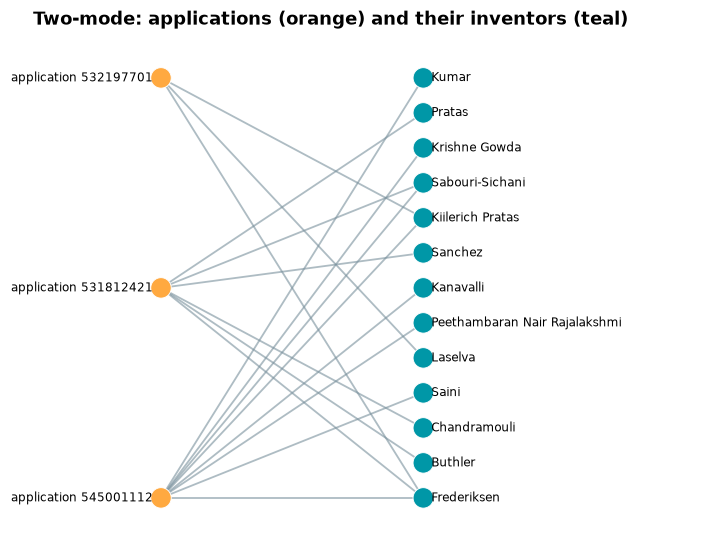

In [ ]:
# A small window: three applications that share inventors
inv = "FREDERIKSEN, Frank"
apps = list(B.neighbors(inv))[:3]
small = B.subgraph(apps + [i for a in apps for i in B.neighbors(a)])

left = [n for n in small if B.nodes[n]["bipartite"] == "application"]
pos_b = nx.bipartite_layout(small, left)                 # applications left, inventors right
colors = [ORANGE if n in left else TEAL for n in small]

ax = draw(small, pos_b, node_size=180, node_color=colors, width=1.2, edge_alpha=0.6,
          title="Two-mode: applications (orange) and their inventors (teal)")
for n, (x, y) in pos_b.items():
    label = f"application {n}  " if n in left else "  " + n.split(",")[0].title()
    ax.text(x, y, label, fontsize=8, va="center", ha="right" if n in left else "left")
ax.set_xlim(-1.6, 1.6)
plt.show()

### Two-mode facts (visible *only* before projecting)

- **Team size** = degree of an application node (how many inventors it has).
- **Productivity** = degree of an inventor node (how many applications they are on).

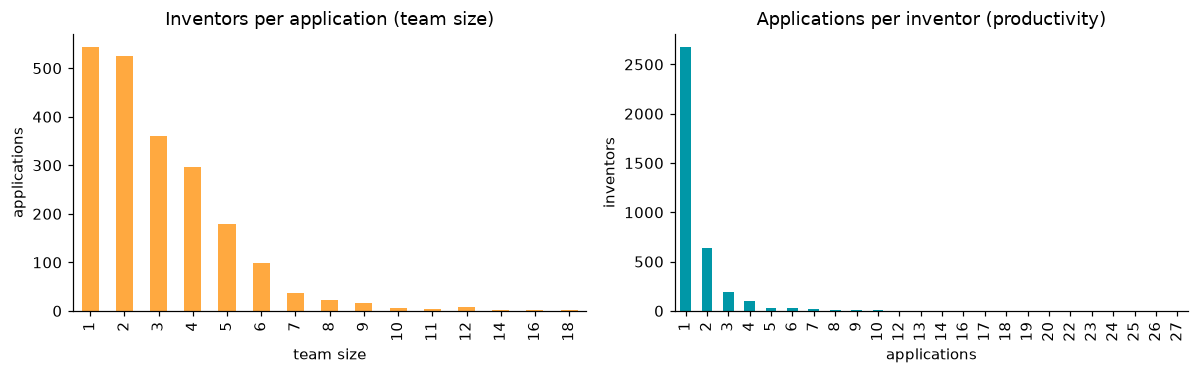

median team size 2, largest team 18
most productive inventors:
NIKOLIC, Miroslav                27
SVENDSEN, Simon                  26
CAPORAL DEL BARRIO, Samantha     26
KIILERICH PRATAS, Nuno Manuel    26
HARREBEK, Johannes               25
dtype: int64


In [ ]:
team_size    = pd.Series({a: B.degree(a) for a in applications})
productivity = pd.Series({i: B.degree(i) for i in inventors})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
team_size.value_counts().sort_index().plot.bar(ax=axes[0], color=ORANGE)
axes[0].set(title="Inventors per application (team size)", xlabel="team size", ylabel="applications")
productivity.value_counts().sort_index().plot.bar(ax=axes[1], color=TEAL)
axes[1].set(title="Applications per inventor (productivity)", xlabel="applications", ylabel="inventors")
plt.tight_layout(); plt.show()

print(f"median team size {team_size.median():.0f}, largest team {team_size.max()}")
print("most productive inventors:"); print(productivity.nlargest(5))

**Read the plots:** most patents have small teams and most inventors file only one application,
but a few are extremely active. That skew (a long tail) will shape everything that follows.

## 3. Projection: from two modes to one

Most network measures (centrality, communities, ...) are designed for **one-mode** networks.
So we **project**: connect two inventors directly if they share at least one application.

The **weight** of a tie = the number of applications the two share.

In [ ]:
def ordered(H):
    """Same node and edge order on every computer, so layouts and communities are reproducible."""
    R = nx.Graph()
    R.add_nodes_from(sorted(H.nodes(data=True)))
    R.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in H.edges(data=True)))
    return R

G = ordered(bipartite.weighted_projected_graph(B, inventors))
print(G)

# The strongest collaborations
strongest = sorted(G.edges(data="weight"), key=lambda e: e[2], reverse=True)[:5]
pd.DataFrame(strongest, columns=["inventor 1", "inventor 2", "shared applications"])

Graph with 3744 nodes and 7632 edges


,inventor 1,inventor 2,shared applications
0,"BARTNIK JOHANSSON, Dorte","NIKOLIC, Miroslav",21
1,"CAPORAL DEL BARRIO, Samantha","SVENDSEN, Simon",19
2,"Bertram, Jacob","GRØNBORG, Kristian Nitzsch",18
3,"Bertram, Jacob","Kristensen, Lars",18
4,"Bertram, Jacob","Pedersen, Rasmus Klercke",18


### Projection is a matrix product

Write the two-mode network as an **incidence matrix** $X$ (inventors × applications, 1 = "is on").
Then $X X^\top$ is inventors × inventors, and each cell counts the shared applications:
the off-diagonal is the projected weight, the diagonal is each inventor's productivity.

In [ ]:
from scipy import sparse

X = bipartite.biadjacency_matrix(B, row_order=inventors, column_order=applications)
W = (X @ X.T).tocsr()                      # inventors x inventors

i, j = inventors.index(strongest[0][0]), inventors.index(strongest[0][1])
print("X X^T says they share", W[i, j], "applications;  the projection says", strongest[0][2])
print("diagonal of X X^T for inventor i:", W[i, i], "= productivity", productivity[inventors[i]])

X X^T says they share 21 applications;  the projection says 21
diagonal of X X^T for inventor i: 23 = productivity 23


### 🔎 What do we lose when we project?

1. **Which** application linked two inventors (only *how many* remains in the weight).
2. **Team structure**: one patent with 10 inventors becomes 45 ties — it looks like a dense clique.
   Large teams therefore create lots of triangles (remember this when we see high clustering in Part 4).
3. Inventors on **solo** applications become isolated nodes.

In [ ]:
print("a team of 10 becomes", 10 * 9 // 2, "ties")
print("isolated inventors (only solo applications):", nx.number_of_isolates(G))

a team of 10 becomes 45 ties
isolated inventors (only solo applications): 334


## 4. What does the collaboration network look like?

### Components: is everyone connected?
A **connected component** is a group in which everyone can reach everyone else via some path.

In [ ]:
components = sorted(nx.connected_components(G), key=len, reverse=True)
sizes = pd.Series([len(c) for c in components])
print("number of components:", len(components))
print("five largest        :", sizes.head().tolist())
print(f"share in the largest: {sizes[0] / G.number_of_nodes():.1%}")

number of components: 996
five largest        : [205, 80, 70, 68, 56]
share in the largest: 5.5%


The network is **fragmented**: hundreds of small islands (often one firm's R&D team) and a largest connected
component of about 200 inventors. From now on we call that largest component **the core** and study it closely.

Graph with 205 nodes and 814 edges


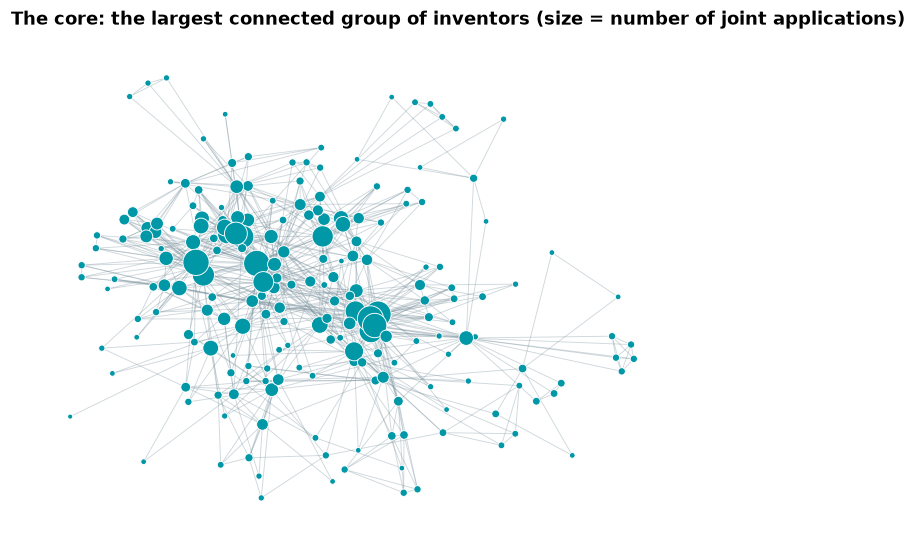

In [ ]:
core = ordered(G.subgraph(components[0]))
pos = nx.spring_layout(core, seed=7, k=0.25)      # fixed seed -> the same picture every time
print(core)

strength = dict(core.degree(weight="weight"))
draw(core, pos, node_size=[8 + 3 * strength[n] for n in core], width=0.6,
     title="The core: the largest connected group of inventors (size = number of joint applications)")
plt.show()

## 🧑‍💻 Your turn

1. Which application has the largest team? List its inventors with `B.neighbors(app)`.
2. Draw the *second*-largest component. Does it look different from the core?
3. Instead of `weighted_projected_graph`, try `bipartite.projected_graph(B, inventors)`. What is lost?

<details><summary>Hints</summary>

```python
app = team_size.idxmax(); list(B.neighbors(app))
second = G.subgraph(components[1]); draw(second, nx.spring_layout(second, seed=1))
```
</details>

In [ ]:
# your code here

## ✅ Key takeaways
- Patent data is **two-mode**: inventors ↔ applications. Some facts (team size) only exist in this form.
- **Projection** gives an inventor–inventor network; weight = shared applications; it equals $XX^\top$.
- Projection loses information and turns teams into cliques.
- The network is **fragmented**; we focus on its largest connected component, **the core**.

**Next → Part 3:** inside the core, *who matters*?